## 1. Set up the python session

### 1.1 Import packages

In [1]:
# Import packages
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
import statsmodels.formula.api as smf
from scipy import stats

### 1.2 Set project folder paths

In [2]:
# file path to import data
root_fldr = Path.cwd().parent
raw_fldr = root_fldr / 'data' / 'raw'
processed_fldr = root_fldr / 'data' / 'processed'

## 2. Load Table and Inspection

### 2.1 Load county table

In [3]:
county_table = pd.read_csv(
    processed_fldr/'County_Income_CFP_Fire_2022_2024.csv',
    )

### 2.2 Inspect county table

In [4]:
county_table.shape

(58, 8)

In [5]:
county_table.isna().sum()

county                0
policies_2022         0
policies_2023         0
policies_2024         0
policy_growth_pct     0
Median_income         0
acres_burned_total    0
income_group          0
dtype: int64

In [6]:
# Count counties with no acres burned
no_fire_mask = county_table["acres_burned_total"] == 0

no_fire_mask.sum()

np.int64(5)

In [7]:
# List the 10 counties with the fewest FAIR Plan policies in 2022
(
    county_table
    [['county', 'policies_2022', 'policies_2024', 'policy_growth_pct']]
    .sort_values('policies_2022')
    .head(10)
)

,county,policies_2022,policies_2024,policy_growth_pct
50,Sutter,20.0,51.0,155.000000
10,Glenn,23.0,49.0,113.043478
5,Colusa,28.0,48.0,71.428571
15,Kings,46.0,117.0,154.347826
24,Modoc,52.0,195.0,275.000000
13,Inyo,55.0,188.0,241.818182
23,Merced,57.0,200.0,250.877193
56,Yolo,62.0,195.0,214.516129
49,Stanislaus,107.0,417.0,289.719626
34,San Benito,112.0,224.0,100.000000


In [8]:
county_table = (
    county_table
    .assign(
        income_10k = lambda df: df['Median_income']/10000,
        log_acres  = lambda df: np.log(df['acres_burned_total']+1),
        small_base = lambda df: df['county'].isin(['Sutter','Glenn','Colusa','Kings']),
    )
)


In [9]:
print(county_table.shape)                
print(county_table['small_base'].sum())  
print(county_table['log_acres'].min())   

(58, 11)
4
0.0


## 5. Add dollars per policy

In [10]:
# 5.1 Load the county income and FAIR Plan file
county_income = pd.read_csv(
    processed_fldr/'County_Income_CFP_2022_2024.csv',
    dtype={'GEOID': 'str'},
    )
print(county_income.shape)

(174, 7)


In [11]:
# 5.2 Keep the 2022 rows
cfp_2022 = county_income.query('year == 2022')
print(cfp_2022.shape)

(58, 7)


In [12]:
# 5.3 Add dollars of exposure per policy
cfp_2022 = cfp_2022.assign(
    dollars_per_policy = lambda df: df['exposure'] / df['policies'],
)


In [13]:
# 5.4 Keep only the county name and the new column
cfp_2022 = cfp_2022[['county', 'dollars_per_policy']]
cfp_2022.head()


,county,dollars_per_policy
0,Alameda,1.031035e+06
1,Alpine,6.807953e+05
2,Amador,6.949849e+05
3,Butte,6.643353e+05
4,Calaveras,7.117833e+05


In [14]:
# 5.5 Left join: add dollars per policy to the county table
county_table = pd.merge(
    county_table,
    cfp_2022,
    on='county',
    how='left',
    indicator=True,
)
county_table['_merge'].value_counts()   


_merge
both          58
left_only      0
right_only     0
Name: count, dtype: int64

In [15]:
# 5.6 Remove the join-check column
county_table = county_table.drop(columns=['_merge'])
print(county_table.shape)   


(58, 12)


## 6. Hisograms

### 6.1 Policy growth

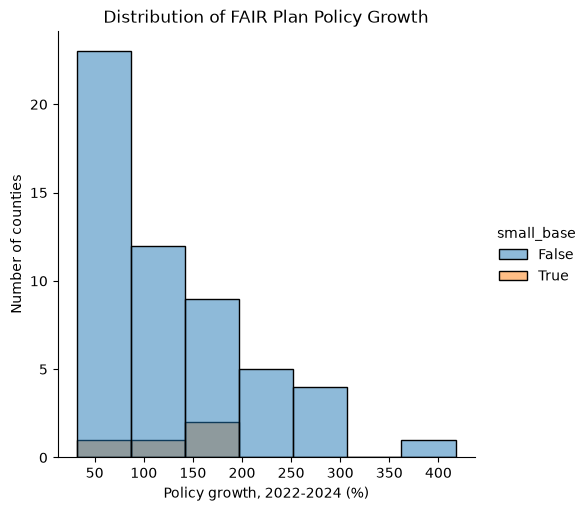

In [16]:
# 6.1 Distribution of policy growth, flagged counties in a second colour
g = sns.displot(
    data=county_table,
    x='policy_growth_pct',
    hue='small_base',
).set(
    title  = 'Distribution of FAIR Plan Policy Growth',
    xlabel = 'Policy growth, 2022-2024 (%)',
    ylabel = 'Number of counties',
);


### 6.2 Raw acres burned

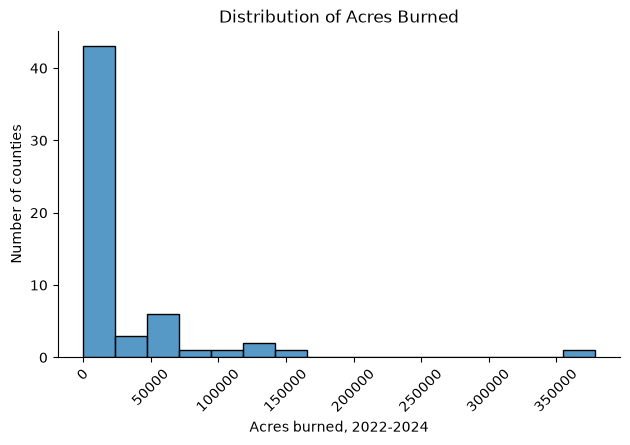

In [17]:
# 6.2 Distribution of acres burned
g = sns.displot(
    data=county_table,
    x='acres_burned_total',
    height=4,
    aspect=1.6,
).set(
    title  = 'Distribution of Acres Burned',
    xlabel = 'Acres burned, 2022-2024',
    ylabel = 'Number of counties',
);
g.tick_params(axis='x', rotation=45);

### 6.3 Log acres

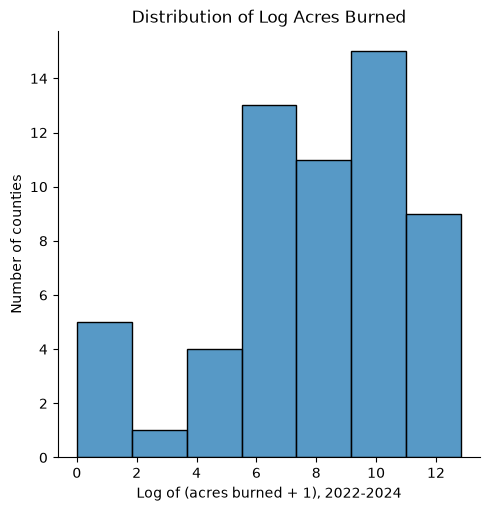

In [18]:
# 6.3 Distribution of log acres burned
g = sns.displot(
    data=county_table,
    x='log_acres',
).set(
    title  = 'Distribution of Log Acres Burned',
    xlabel = 'Log of (acres burned + 1), 2022-2024',
    ylabel = 'Number of counties',
);


## 7.

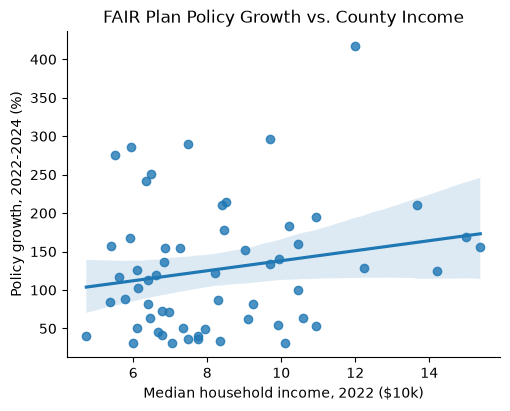

In [19]:
# 7.1 Income vs policy growth with a fitted line
g = sns.lmplot(
    data=county_table,
    x='income_10k',
    y='policy_growth_pct',
    height=4,
    aspect=1.3,
).set(
    title  = 'FAIR Plan Policy Growth vs. County Income',
    xlabel = 'Median household income, 2022 ($10k)',
    ylabel = 'Policy growth, 2022-2024 (%)',
);

In [20]:
# 7.2 Fit a straight line: policy growth explained by income
m_income = smf.ols("policy_growth_pct ~ income_10k", data=county_table).fit()


In [21]:
# 7.3 Show the model results
m_income.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.038
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     2.223
Date:                Sun, 15 Nov 2026   Prob (F-statistic):              0.142
Time:                        15:34:51   Log-Likelihood:                -337.13
No. Observations:                  58   AIC:                             678.3
Df Residuals:                      56   BIC:                             682.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     72.9931     37.809      1.931      0.059      -2.748     148.734
income_10k     6.5108      4.367      1.491      0.142      -2.237      15.258
==============================================================================
Omnibus:                       13.228   Durbin-Watson:                   1.772
Prob(Omnibus):                  0.001   Jarque-Bera (JB):               13.988
Skew:                           1.113   Prob(JB):                     0.000917
Kurtosis:                       3.914   Cond. No.                         30.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

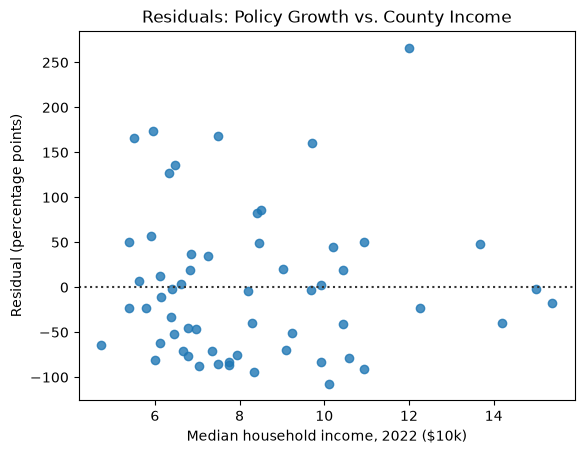

In [22]:
# 7.4 Residuals: distance of each county from the fitted line
sns.residplot(
    data=county_table,
    x='income_10k',
    y='policy_growth_pct',
).set(
    title  = 'Residuals: Policy Growth vs. County Income',
    xlabel = 'Median household income, 2022 ($10k)',
    ylabel = 'Residual (percentage points)',
);


In [23]:
# 7.5 Drop the four small-base counties
county_no_small = county_table.query('small_base == False')
print(county_no_small.shape)   # (54, 12)


(54, 12)


In [24]:
# 7.6 Refit the income model without the four small-base counties
m_income_no_small = smf.ols("policy_growth_pct ~ income_10k", data=county_no_small).fit()


In [25]:
# 7.7 Show the results without the four small-base counties
m_income_no_small.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.039
Model:                            OLS   Adj. R-squared:                  0.020
Method:                 Least Squares   F-statistic:                     2.083
Date:                Sun, 15 Nov 2026   Prob (F-statistic):              0.155
Time:                        15:34:51   Log-Likelihood:                -315.47
No. Observations:                  54   AIC:                             634.9
Df Residuals:                      52   BIC:                             638.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     71.9511     40.035      1.797      0.078      -8.384     152.287
income_10k     6.5843      4.562      1.443      0.155      -2.570      15.738
==============================================================================
Omnibus:                       12.055   Durbin-Watson:                   1.825
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               12.356
Skew:                           1.110   Prob(JB):                      0.00207
Kurtosis:                       3.753   Cond. No.                         30.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Policy growth rose by about 6.5 percentage points per $10,000 of median income, but the slope was not distinguishable from zero (p = 0.14, R² = 0.04), and this was unchanged without the four small-base counties (slope 6.6, p = 0.16).



## 8. 

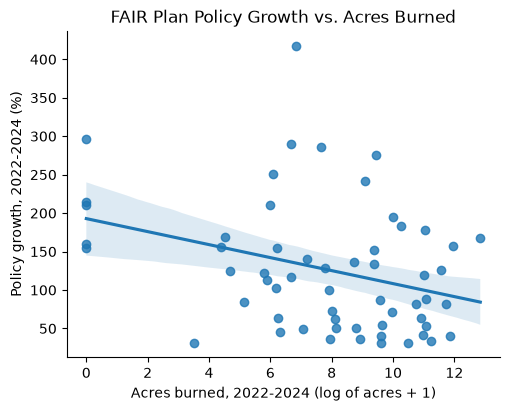

In [26]:
# 8.1 Acres burned vs policy growth with a fitted line
g = sns.lmplot(
    data=county_table,
    x='log_acres',
    y='policy_growth_pct',
    height=4,
    aspect=1.3,
).set(
    title  = 'FAIR Plan Policy Growth vs. Acres Burned',
    xlabel = 'Acres burned, 2022-2024 (log of acres + 1)',
    ylabel = 'Policy growth, 2022-2024 (%)',
);


In [27]:
# 8.2 Fit a straight line: policy growth explained by acres burned
m_fire = smf.ols("policy_growth_pct ~ log_acres", data=county_table).fit()


In [28]:
# 8.3 Show the model results
m_fire.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.110
Model:                            OLS   Adj. R-squared:                  0.094
Method:                 Least Squares   F-statistic:                     6.939
Date:                Sun, 15 Nov 2026   Prob (F-statistic):             0.0109
Time:                        15:34:51   Log-Likelihood:                -334.87
No. Observations:                  58   AIC:                             673.7
Df Residuals:                      56   BIC:                             677.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    192.8440     27.071      7.124      0.000     138.614     247.074
log_acres     -8.4519      3.209     -2.634      0.011     -14.880      -2.024
==============================================================================
Omnibus:                       16.447   Durbin-Watson:                   1.972
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               19.556
Skew:                           1.181   Prob(JB):                     5.67e-05
Kurtosis:                       4.585   Cond. No.                         22.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

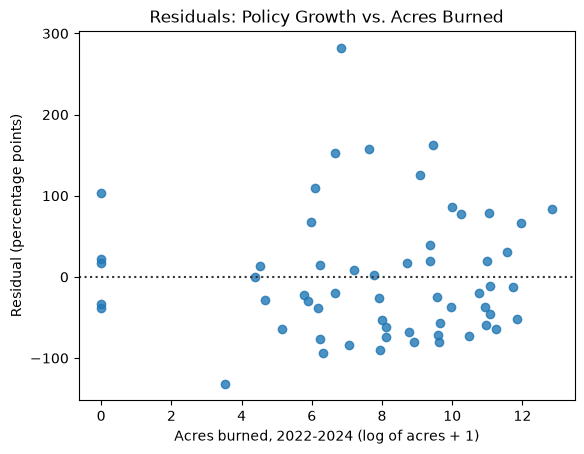

In [29]:
# 8.4 Residuals: distance of each county from the fitted line
sns.residplot(
    data=county_table,
    x='log_acres',
    y='policy_growth_pct',
).set(
    title  = 'Residuals: Policy Growth vs. Acres Burned',
    xlabel = 'Acres burned, 2022-2024 (log of acres + 1)',
    ylabel = 'Residual (percentage points)',
);


Policy growth fell by about 8.5 percentage points for each one-unit increase in log acres burned (p = 0.011, R² = 0.11), so counties that burned more between 2022 and 2024 saw slower FAIR Plan growth.



## 9.

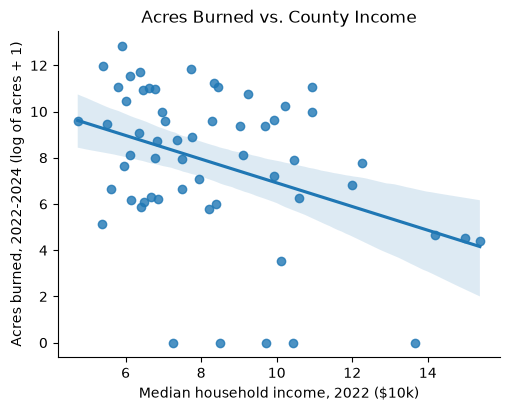

In [30]:
# 9.1 Income vs acres burned with a fitted line
g = sns.lmplot(
    data=county_table,
    x='income_10k',
    y='log_acres',
    height=4,
    aspect=1.3,
).set(
    title  = 'Acres Burned vs. County Income',
    xlabel = 'Median household income, 2022 ($10k)',
    ylabel = 'Acres burned, 2022-2024 (log of acres + 1)',
);


In [31]:
# 9.2 Correlation between income and acres burned
stats.pearsonr(county_table['income_10k'], county_table['log_acres'])


PearsonRResult(statistic=np.float64(-0.3915810937537153), pvalue=np.float64(0.00236841502796867))

Median income and log acres burned were negatively correlated (r = −0.39, p = 0.002), so higher-income counties burned less between 2022 and 2024.



## 10. 

In [32]:
# 10.1 Fit growth explained by income and acres burned together
m_both = smf.ols("policy_growth_pct ~ income_10k + log_acres", data=county_table).fit()


In [33]:
# 10.2 Show the model results
m_both.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.115
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     3.584
Date:                Sun, 15 Nov 2026   Prob (F-statistic):             0.0344
Time:                        15:34:52   Log-Likelihood:                -334.71
No. Observations:                  58   AIC:                             675.4
Df Residuals:                      55   BIC:                             681.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    165.4982     55.892      2.961      0.005      53.488     277.508
income_10k     2.5733      4.593      0.560      0.578      -6.631      11.777
log_acres     -7.6821      3.509     -2.189      0.033     -14.714      -0.651
==============================================================================
Omnibus:                       15.884   Durbin-Watson:                   1.916
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               18.311
Skew:                           1.182   Prob(JB):                     0.000106
Kurtosis:                       4.411   Cond. No.                         62.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [34]:
# 10.3 Standardize income and log acres (mean 0, standard deviation 1)
county_table = (
    county_table
    .assign(
        income_z    = lambda df: (df['income_10k'] - df['income_10k'].mean()) / df['income_10k'].std(),
        log_acres_z = lambda df: (df['log_acres'] - df['log_acres'].mean()) / df['log_acres'].std(),
    )
)


In [35]:
# 10.4 Check: each new column has mean 0 and standard deviation 1
county_table[['income_z', 'log_acres_z']].agg(['mean', 'std'])


,income_z,log_acres_z
mean,1.531342e-17,-3.014830e-16
std,1.000000e+00,1.000000e+00


In [36]:
# 10.5 Refit with the standardized columns
m_both_z = smf.ols("policy_growth_pct ~ income_z + log_acres_z", data=county_table).fit()


In [37]:
# 10.6 Show the standardized results
m_both_z.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      policy_growth_pct   R-squared:                       0.115
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     3.584
Date:                Sun, 15 Nov 2026   Prob (F-statistic):             0.0344
Time:                        15:34:52   Log-Likelihood:                -334.71
No. Observations:                  58   AIC:                             675.4
Df Residuals:                      55   BIC:                             681.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     127.0110     10.467     12.134      0.000     106.034     147.988
income_z        6.4295     11.475      0.560      0.578     -16.567      29.426
log_acres_z   -25.1240     11.475     -2.189      0.033     -48.120      -2.128
==============================================================================
Omnibus:                       15.884   Durbin-Watson:                   1.916
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               18.311
Skew:                           1.182   Prob(JB):                     0.000106
Kurtosis:                       4.411   Cond. No.                         1.51
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

With both in one model, acres burned remained associated with lower policy growth (−7.7 per log acre, p = 0.033) while income did not (2.6 per $10k, p = 0.58); in standardized units the acres effect (−25.1) was about four times the income effect (6.4).



## 11.

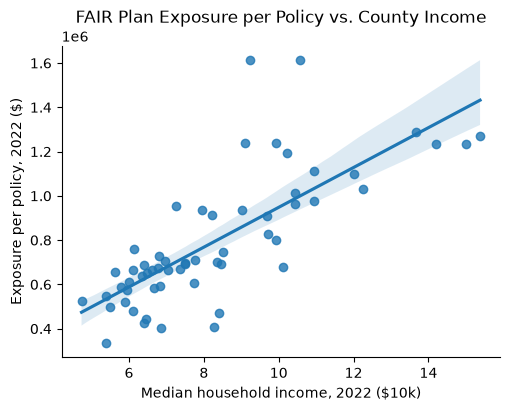

In [38]:
# 11.1 Income vs dollars of exposure per policy with a fitted line
g = sns.lmplot(
    data=county_table,
    x='income_10k',
    y='dollars_per_policy',
    height=4,
    aspect=1.3,
).set(
    title  = 'FAIR Plan Exposure per Policy vs. County Income',
    xlabel = 'Median household income, 2022 ($10k)',
    ylabel = 'Exposure per policy, 2022 ($)',
);


In [39]:
# 11.2 Correlation between income and dollars per policy
stats.pearsonr(county_table['income_10k'], county_table['dollars_per_policy'])


PearsonRResult(statistic=np.float64(0.7618375010924323), pvalue=np.float64(3.786895699824088e-12))

* `County_Validation_Analysis.ipynb` tests the patterns from our exploratory analysis using the county table: regressions of Fair Plan policy growth on income and on acres burned (separately and together), a check without the four smallest counties, and correlations of income with acres burned and with exposure per policy.
